# Nearest neighbour searches

*Python port of the R vignette [Nearest neighbour searches in manifoldsR](https://gregorlueg.github.io/manifoldsR/articles/knn_searches.html). Original author: Gregor Lueg.*

kNN graphs sit underneath nearly every method in this package. UMAP, densMAP,
t-SNE, PaCMAP, LocalMAP, PHATE, diffusion maps and ForceAtlas2 all start from
one. This vignette walks through the backends, what each is good at, how
exact the approximate ones are, and how to build a graph once and hand it to
several estimators instead of recomputing it every time.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import manifolds_rs as mf

K = 10

## Exhaustive search

The simplest one. A flat index with SIMD distance kernels, so it is cache
friendly and on small data it beats the approximate searches, which have to
build an index first. `knn_graph` hands back indices and distances as two
`(n_samples, k)` arrays, self excluded.

In [2]:
X, labels = mf.datasets.clustered(1_000)

indices, distances = mf.knn_graph(X, k=K, ann="exhaustive")

print(indices.shape, indices.dtype, distances.dtype)
indices[:3]

(1000, 10) int64 float64


array([[625, 320, 442, 817,  59, 447, 491, 235, 206, 205],
       [ 75, 759, 926, 825, 335, 993, 569, 557, 535, 892],
       [932, 983, 915, 743, 253, 163, 329, 873,  20, 479]])

Indices first, distances second. That is the opposite of scikit-learn's
`kneighbors`, and it is the order every estimator takes them in.

An exact alternative is
[kMkNN](https://ieeexplore.ieee.org/document/6033373) (k-means for k-nearest
neighbours). It clusters the data with k-means and uses the triangle
inequality to skip most of the distance computations. Very fast on data with
strong structure and modest dimensionality, and the default of `knn_graph`.

In [3]:
indices_kmknn, _ = mf.knn_graph(X, k=K, ann="kmknn")

np.array_equal(indices, indices_kmknn)

True

## Approximate searches

The package is built for large data and pulls its approximate searches from
[ann-search-rs](https://github.com/GregorLueg/ann-search-rs). Five of them
are exposed, on top of the two exact ones. Default wheels add a sixth,
`"rinnd"`, from Leland McInnes' [rinnd](https://github.com/lmcinnes/rinnd):

| Method | Class | Use case |
| --- | --- | --- |
| `"balltree"` | Tree | Small data, low dimensionality. |
| `"annoy"` | Tree | A single-cell classic. Scales to a few hundred thousand points at low dimensionality. |
| `"hnsw"` | Graph | Large data (500k and up), any dimensionality. Slower build, fast queries. The build uses a benign race. |
| `"nndescent"` | Graph | The all-rounder from 100k points on. Default for UMAP, densMAP, ForceAtlas2 and diffusion maps. |
| `"rinnd"` | Graph | rinnd's NN-Descent. Its SIMD kernels are tuned for x86 (AVX2), so it is the one to try there. `mf.rinnd_available()` says whether your build has it. |
| `"ivf"` | Cluster | The index behind FAISS. Large data, any dimensionality. `n_probes` trades recall for speed. Default for the t-SNE family, PaCMAP, LocalMAP and PHATE. |

Every backend bar `"exhaustive"` searches in float32, whatever you hand it,
and casts the distances back to your dtype. Same recall, less memory traffic.
The knobs per backend live in `NeighbourParams`; only the fields of the
backend you picked do anything.

In [4]:
mf.NeighbourParams()

NeighbourParams(n_tree=None, search_budget=None, m=None, ef_construction=None, ef_search=None, delta=None, nnd_n_trees=None, bt_budget=None, n_list=None, n_probes=None, k_means=None)

### Speed

Every backend at three sizes, one run each.

In [5]:
BACKENDS = ["exhaustive", "kmknn", "balltree", "annoy", "hnsw", "nndescent", "ivf"]
if mf.rinnd_available():
    BACKENDS.insert(-1, "rinnd")


def timed(fn) -> float:
    """Wall time of one call, in seconds."""
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start


def time_backends(X: np.ndarray) -> dict[str, float]:
    """Wall time of every backend on `X`."""
    params = mf.NeighbourParams(n_probes=25)
    return {
        ann: timed(lambda ann=ann: mf.knn_graph(X, k=K, ann=ann, nn_params=params))
        for ann in BACKENDS
    }


speed = {
    f"{n // 1000}k": time_backends(mf.datasets.clustered(n)[0])
    for n in (1_000, 50_000, 100_000)
}

pl.DataFrame(
    {"method": list(speed["1k"]), **{n: list(t.values()) for n, t in speed.items()}}
).with_columns(pl.exclude("method").round(3))

method,1k,50k,100k
str,f64,f64,f64
"""exhaustive""",0.002,0.801,3.17
"""kmknn""",0.014,0.184,0.501
"""balltree""",0.002,0.314,1.173
"""annoy""",0.008,0.994,3.172
"""hnsw""",0.008,0.989,2.958
"""nndescent""",0.005,0.146,0.351
"""rinnd""",0.006,0.242,0.541
"""ivf""",0.029,0.175,0.383


Times in seconds. On 1k points nothing matters: exhaustive is as fast as
anything, since every other backend has to build an index first and SIMD does
the `O(N^2)` in no time at that size. From 50k on NN-Descent and IVF are the
fastest, and the gap grows with N. kMkNN, which is exact, is close behind at
50k and takes a quarter to a sixth of the exhaustive time on this tightly
clustered data. rinnd trails the other NN-Descent here, level with kMkNN,
without its x86 kernels (more on that below).

Annoy and HNSW are no faster than exhaustive here: a one-off self-query at
`k = 10` never pays back their index build. They earn their keep at larger N,
or when you query the same index again and again.

### Precision

Approximate means approximate. Two numbers against the exhaustive ground
truth on 25k points:

- Recall@k: fraction of the true `k` neighbours found, in any order.
- Mean distance ratio: distance to the found neighbour over the distance to
  the true one at the same rank. `1.0` is perfect, and it tells you how wrong
  the misses are.

In [6]:
X_25k, _ = mf.datasets.clustered(25_000)
true_idx, true_dist = mf.knn_graph(X_25k, k=K, ann="exhaustive")


def precision(ann: str) -> dict[str, float | str]:
    """Recall@k and mean distance ratio of one backend against exhaustive."""
    idx, dist = mf.knn_graph(
        X_25k, k=K, ann=ann, nn_params=mf.NeighbourParams(n_probes=25)
    )
    hits = sum(len(set(a) & set(b)) for a, b in zip(idx, true_idx, strict=True))
    return {
        "method": ann,
        "recall": hits / true_idx.size,
        "dist_ratio": float(np.mean(dist / true_dist)),
    }


pl.DataFrame([precision(ann) for ann in BACKENDS[1:]]).with_columns(
    pl.col("recall", "dist_ratio").round(4)
)

method,recall,dist_ratio
str,f64,f64
"""kmknn""",1.0,1.0
"""balltree""",0.932,1.0023
"""annoy""",0.9999,1.0
"""hnsw""",0.9989,1.0
"""nndescent""",0.923,1.002
"""rinnd""",0.7767,1.0078
"""ivf""",0.9935,1.0002


Look at the distance ratio before you panic about a recall number. The
synthetic clusters are tight, so lots of points sit at nearly identical
distances and swapping one for another costs nothing. For manifold learning
that is exactly the kind of miss you don't care about. rinnd is the clearest
case: the lowest recall in the table, but its misses still sit within a
percent of the true distances. Part of that gap is its smaller forest, see
the next section. For a much deeper
comparison of the methods, see the
[ann-search-rs benchmarks](https://github.com/GregorLueg/ann-search-rs).

### Seeding NN-Descent

Both NN-Descents start the same way. A forest of random projection trees
splits the data into small leaves, every point takes its leaf mates as its
first guess at its neighbours, and the descent then refines that graph by
checking neighbours of neighbours until few edges change. More trees means a
better first guess and fewer descent iterations, at a higher upfront cost.

The two disagree on how many trees to plant. `"nndescent"` follows scanpy
(and umap-learn's compatibility layout): `5 + sqrt(n) / 20`, capped at 64.
`"rinnd"` follows PyNNDescent's own default: `2 * log10(n)`, clamped to
`[3, 12]`. So the ann-search-rs index bets on the forest, with a count that
grows with the square root of the data, and rinnd bets on the descent, with a
count that barely moves. The gap opens up with the data: about 1.5x at 25k
points, twice the trees at 100k, and nearly five times at a million cells.

In [7]:
pl.DataFrame({"n": [1_000, 25_000, 100_000, 1_000_000, 5_000_000]}).with_columns(
    nndescent=(5 + (pl.col("n").sqrt() / 20).round()).clip(upper_bound=64),
    rinnd=(2 * pl.col("n").log10()).round().clip(3, 12),
).cast(pl.Int64)

n,nndescent,rinnd
i64,i64,i64
1000,7,6
25000,13,9
100000,21,10
1000000,55,12
5000000,64,12


`nnd_n_trees` in `NeighbourParams` overrides either. Here both NN-Descents run
at their own default and at the other one's, on 100k points at `k = 15`:

In [8]:
X_100k, _ = mf.datasets.clustered(100_000)
truth_100k, truth_dist_100k = mf.knn_graph(X_100k, k=15, ann="kmknn")

# The two defaults at n = 100k, as in the table above.
n = X_100k.shape[0]
DEFAULT_TREES = {
    "nndescent": min(64, 5 + round(n**0.5 / 20)),
    "rinnd": max(3, min(12, round(2 * np.log10(n)))),
}


def seeded(ann: str, n_trees: int) -> dict[str, float | str | bool]:
    """Wall time, recall and mean distance ratio of one NN-Descent."""
    params = mf.NeighbourParams(nnd_n_trees=n_trees)
    start = time.perf_counter()
    idx, dist = mf.knn_graph(X_100k, k=15, ann=ann, nn_params=params)
    elapsed = time.perf_counter() - start
    hits = sum(len(set(a) & set(b)) for a, b in zip(idx, truth_100k, strict=True))
    return {
        "method": ann,
        "n_trees": n_trees,
        "default": n_trees == DEFAULT_TREES[ann],
        "seconds": elapsed,
        "recall": hits / truth_100k.size,
        "dist_ratio": float(np.mean(dist / truth_dist_100k)),
    }


methods = ["nndescent", "rinnd"] if mf.rinnd_available() else ["nndescent"]
pl.DataFrame(
    [seeded(ann, t) for ann in methods for t in DEFAULT_TREES.values()]
).with_columns(pl.col("seconds").round(3), pl.col("recall", "dist_ratio").round(4))

method,n_trees,default,seconds,recall,dist_ratio
str,i64,bool,f64,f64,f64
"""nndescent""",21,true,0.48,0.9292,1.0017
"""nndescent""",10,false,0.441,0.9232,1.0019
"""rinnd""",21,false,0.894,0.8055,1.0059
"""rinnd""",10,true,0.78,0.7499,1.0084


On this data the tree count moves rinnd more than it moves `"nndescent"`.
Giving rinnd the scanpy count buys recall at a modest extra cost, while cutting
`"nndescent"` down to rinnd's count saves a little time and loses very little.
The distance ratio barely moves for either: the extra misses are near-ties.

These docs render on Apple Silicon, where rinnd's AVX2 kernels do not run and
ann-search-rs gets Accelerate for its GEMMs. So read the timings as one
machine's, not a ranking. On x86 the picture can flip, and that is where
`"rinnd"` is worth a benchmark on your own data.

## Build once, embed many times

On anything large the neighbour search is most of the runtime. Running UMAP
with three different `min_dist` values, plus t-SNE, plus PaCMAP? Build the
graph once and pass it in. Each estimator takes `knn_indices` and
`knn_distances` in `fit` / `fit_transform`.

Mind the width. UMAP takes `n_neighbors` neighbours and cuts a wider graph
down (with a warning on stderr). t-SNE wants `3 * perplexity`. PaCMAP and
LocalMAP want `n_near + 50`, because the near pairs are the best `n_near` of a
wider search by locally scaled distance. So build the widest one you need.

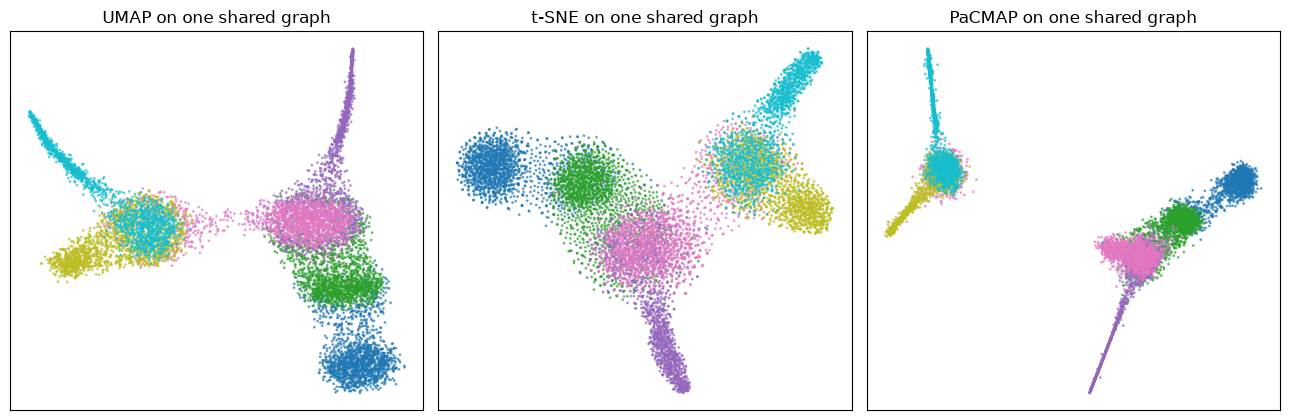

In [9]:
X_traj, labels_traj = mf.datasets.trajectory(10_000)

idx, dist = mf.knn_graph(X_traj, k=90, ann="nndescent")

embeddings = {
    "UMAP": mf.UMAP().fit_transform(
        X_traj, knn_indices=idx[:, :15], knn_distances=dist[:, :15]
    ),
    "t-SNE": mf.TSNE(perplexity=30.0).fit_transform(
        X_traj, knn_indices=idx, knn_distances=dist
    ),
    "PaCMAP": mf.PaCMAP().fit_transform(
        X_traj, knn_indices=idx[:, :60], knn_distances=dist[:, :60]
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (name, emb) in zip(axes, embeddings.items(), strict=True):
    ax.scatter(emb[:, 0], emb[:, 1], c=labels_traj, s=1, cmap="tab10", alpha=0.6)
    ax.set_title(f"{name} on one shared graph")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

One search, three embeddings. The graph is just two numpy arrays, so you can
also build it on the GPU and run the embedding on the CPU, or the other way
round. The [GPU vignette](../gpu/) has that.